# Assignment 09, Problem 4 — Hussein Jawad
**E89 Deep Learning · Speech command recognition: a Conv2D model on MFCC arrays** (based on Lecture 9, the class notebook
`lec09_speech_command_recognition.ipynb` and Problems 2–3)

---

# Problem 4: Conv2D model on MFCCs of every 3rd frame
Please make a copy of the notebook developed in Problem 3. Use new notebook and modify your M5 model so that instead of
Conv1D layers with target of length 80 it uses Conv2D layers with the target of dimensions 3x3. For increased speed reduce
the number of Conv2D layers to 2. As an input into new model use arrays of MFCC-s similar to the ones used in Problem 2.
Do not use MFCC-s for every frame of your recording but use every 3rd frame. You will have to reconstitute your
DataLoaders for train, validate and test datasets. Generate similar diagrams for loss and accuracy as the ones in
Problem 3. Use the test set to evaluate the actual accuracy of the model. Display the number of trainable parameters of
new model. Make a general comparison with the model in Problem 3. Just state the observations.

## Approach

### Goal
Replace the M5 network (four Conv1D layers on the raw waveform) with a small CNN of **two Conv2D layers with 3×3
filters** that reads each recording as a small **MFCC image**, train and test it exactly as in Problem 3, and compare.

### Input: one MFCC array per recording (as in Problem 2)

| | Value |
|---|---|
| Recording | 1 s at 16 kHz (shorter recordings padded with zeros) |
| Frames | 25 ms, stride 10 ms, Hann window → 98 frames |
| MFCCs | first 12 ($c_0 \dots c_{11}$), 40 mel filters |
| Every 3rd frame | 33 frames → array of **12 × 33** |

### Steps

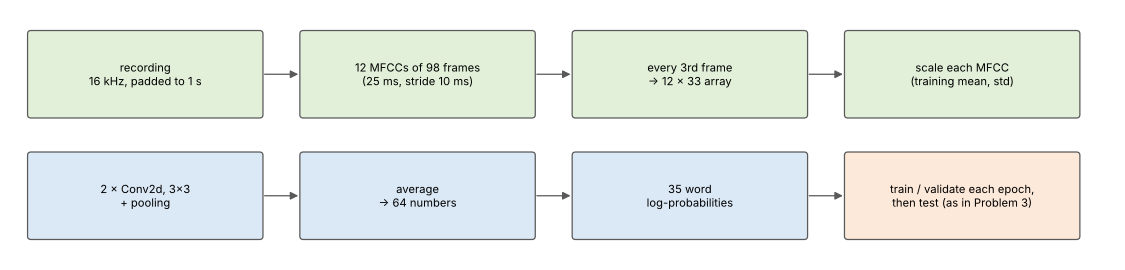

1. **Load** the dataset and labels as in Problem 3 (Steps 2–3).
2. **Compute** the 12 × 33 MFCC array of every recording and scale each coefficient with training-set statistics (Step 4).
3. **Rebuild** the DataLoaders for training, validation and testing from these arrays (Step 5).
4. **Build** the 2-layer Conv2D model and count its trainable parameters (Step 6).
5. **Train** for 25 epochs with validation after each epoch, **plot** the curves and **test**, as in Problem 3 (Steps 7–11).

### Changes to the Problem 3 notebook
Changed or added lines are marked `# CHANGED` or `# NEW` in the code.
* Input: MFCC arrays (12 × 33) instead of raw audio resampled to 8 kHz (the resampling and `collate_fn` are not needed).
* DataLoaders: built from the precomputed arrays with `TensorDataset`, as in the lab notebook.
* Model: two `Conv2d` layers with 3×3 filters instead of four `Conv1d` layers (first filter 80 samples long).
* Everything else (dataset, labels, optimizer, learning-rate schedule, batch size, number of epochs, `train()`, `test()`,
  plots, test) is the same as in Problem 3.

## Solution

### Step 1: Install torchcodec, imports, versions and device (as in Problem 3)

In [ ]:
%pip install -q torchcodec  # torchaudio reads the recordings with torchcodec (as in Problem 3)

In [ ]:
import torch                                 # PyTorch
import torch.nn as nn                        # neural-network layers
import torch.nn.functional as F              # relu, log_softmax, nll_loss, ...
import torch.optim as optim                  # optimizers and learning-rate schedulers
import torchaudio                            # the dataset
import torchcodec                            # decodes the audio files for torchaudio (class notebook)
import numpy as np                           # NEW: numerical arrays
import librosa                               # NEW: MFCCs, as in Problem 2
from torch.utils.data import TensorDataset, DataLoader  # NEW: data sets and loaders built from tensors (lab notebook)

import matplotlib.pyplot as plt              # plotting

In [ ]:
print("torch: ", torch.__version__)          # PyTorch version
print("torchaudio: ", torchaudio.__version__)  # torchaudio version
print("torchcodec: ", torchcodec.__version__)  # torchcodec version
print("librosa: ", librosa.__version__)      # NEW: librosa version

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # use the GPU when there is one
print(device)                                # cuda or cpu
torch.manual_seed(0)                         # same initial weights and batch order on every run

### Step 2: The dataset (as in Problem 3)

In [ ]:
from torchaudio.datasets import SPEECHCOMMANDS                    # the Speech Commands dataset
import os                                                         # file paths

class SubsetSC(SPEECHCOMMANDS):                                   # the class notebook's dataset with the official splits
    def __init__(self, subset: str = None):                        # subset = "training", "validation" or "testing"
        super().__init__("./", download=True)                      # downloads and unpacks the data only if not there yet

        def load_list(filename):                                   # reads one of the official split lists
            filepath = os.path.join(self._path, filename)          # e.g. ./SpeechCommands/.../validation_list.txt
            with open(filepath) as fileobj:                        # open the list
                return [os.path.normpath(os.path.join(self._path, line.strip())) for line in fileobj]  # normpath (as in Problem 3)

        if subset == "validation":                                 # validation files:
            self._walker = load_list("validation_list.txt")        # from the official list
        elif subset == "testing":                                  # test files:
            self._walker = load_list("testing_list.txt")           # from the official list
        elif subset == "training":                                 # training files = all the others
            excludes = load_list("validation_list.txt") + load_list("testing_list.txt")  # files to leave out
            excludes = set(excludes)                               # a set for fast look-up
            self._walker = [w for w in self._walker if os.path.normpath(w) not in excludes]  # normpath (Problem 3)



# Create training, validation and testing splits of the data
train_set = SubsetSC("training")             # training recordings
test_set = SubsetSC("testing")               # test recordings
validation_set = SubsetSC("validation")      # validation recordings (now used after every epoch)

waveform, sample_rate, label, speaker_id, utterance_number = train_set[0]  # the first data point
print("training:", len(train_set), "| validation:", len(validation_set), "| testing:", len(test_set))  # sizes

### Step 3: The labels (label-listing cell disabled, as in Problem 3)

In [ ]:
# DISABLED: the class notebook's label-listing cell (it decodes all 84,843 training recordings)
# labels = sorted(list(set(datapoint[2] for datapoint in train_set)))
# labels

In [ ]:
labels = sorted(d for d in os.listdir(train_set._path)          # the labels are the word-folder names,
                if os.path.isdir(os.path.join(train_set._path, d)) and not d.startswith("_"))  # not _background_noise_
labels                                       # the 35 words

### Step 4: MFCC arrays of every 3rd frame (new input)
Each recording is cut or padded to 1 s, and `librosa.feature.mfcc` computes 12 MFCCs with the Problem 2 settings
(25 ms Hann frames, 10 ms stride, 40 mel filters); every 3rd frame is kept. The recordings are processed 1,000 at a time.
Then each coefficient is scaled to mean 0 and standard deviation 1 using **training** statistics only (as in the lab
notebook; otherwise $c_0$, around −300, would dominate the inputs).

In [ ]:
def label_to_index(word):                    # word -> number 0 ... 34 (as in Problem 3)
    # Return the position of the word in labels
    return torch.tensor(labels.index(word))  # position of the word in labels


def mfcc_arrays(dataset):                                      # NEW: 12 MFCCs of every 3rd frame for each recording
    X, y = [], []                                              # MFCC arrays and label numbers
    for start in range(0, len(dataset), 1000):                 # 1,000 recordings at a time
        waves, targets = [], []                                # one block of recordings
        for i in range(start, min(start + 1000, len(dataset))):  # each recording of the block
            waveform, sample_rate, label, *_ = dataset[i]      # samples (16 kHz), sample rate, word
            w = waveform[0, :16000].numpy()                    # at most 1 s
            waves.append(np.pad(w, (0, 16000 - len(w))))       # shorter recordings: zeros up to 1 s
            targets.append(label_to_index(label))              # label number
        mfcc = librosa.feature.mfcc(y=np.stack(waves), sr=16000, n_mfcc=12,  # Problem 2 settings: 12 MFCCs,
                                    n_fft=400, win_length=400, hop_length=160,  # 25 ms frames every 10 ms,
                                    window="hann", center=False, n_mels=40)    # Hann window, 40 mel filters
        X.append(mfcc[:, :, ::3])                              # every 3rd frame -> [block, 12, 33]
        y += targets                                           # labels of the block
    return torch.tensor(np.concatenate(X)).unsqueeze(1), torch.stack(y)  # [N, 1, 12, 33] and [N]


X_train, y_train = mfcc_arrays(train_set)                      # training arrays
X_val, y_val = mfcc_arrays(validation_set)                     # validation arrays
X_test, y_test = mfcc_arrays(test_set)                         # test arrays

mean = X_train.mean(dim=(0, 3), keepdim=True)                  # mean of each coefficient (training data only)
std = X_train.std(dim=(0, 3), keepdim=True)                    # standard deviation of each coefficient
X_train, X_val, X_test = [(X - mean) / std for X in (X_train, X_val, X_test)]  # same scaling for all three sets
print("MFCC arrays [recordings, channel, MFCCs, frames]:",   # shapes of the three sets
      tuple(X_train.shape), tuple(X_val.shape), tuple(X_test.shape))  # training, validation, test

### Step 5: New DataLoaders for training, validation and testing

In [ ]:
batch_size = 256                             # recordings per batch (as in Problem 3)

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=batch_size, shuffle=True)  # CHANGED: from the arrays
validation_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=batch_size)              # CHANGED
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=batch_size)                  # CHANGED

### Step 6: The new model: two Conv2D layers with 3×3 filters
Written like M5 (convolution → batch normalization → ReLU → max pooling, then averaging and one linear layer), but with
two `Conv2d` layers whose 3×3 filters slide over the MFCC × frame array.

In [ ]:
class M5_2D(nn.Module):                                        # CHANGED: M5 with two Conv2d layers and 3x3 filters
    def __init__(self, n_input=1, n_output=35, n_channel=32):  # 1 input channel, 35 words out
        super().__init__()                                     # set up the nn.Module
        self.conv1 = nn.Conv2d(n_input, n_channel, kernel_size=3, padding=1)        # 32 filters of 3x3
        self.bn1 = nn.BatchNorm2d(n_channel)                   # batch normalization
        self.pool1 = nn.MaxPool2d(2)                           # keeps the largest of every 2x2 block
        self.conv2 = nn.Conv2d(n_channel, 2 * n_channel, kernel_size=3, padding=1)  # 64 filters of 3x3
        self.bn2 = nn.BatchNorm2d(2 * n_channel)               # batch normalization
        self.pool2 = nn.MaxPool2d(2)                           # max pooling
        self.fc1 = nn.Linear(2 * n_channel, n_output)          # 64 features -> 35 word scores

    def forward(self, x):                                      # x: [batch, 1, 12, 33]
        x = self.conv1(x)                                      # block 1: convolution -> [batch, 32, 12, 33]
        x = F.relu(self.bn1(x))                                # batch norm + ReLU
        x = self.pool1(x)                                      # max pooling -> [batch, 32, 6, 16]
        x = self.conv2(x)                                      # block 2: convolution -> [batch, 64, 6, 16]
        x = F.relu(self.bn2(x))                                # batch norm + ReLU
        x = self.pool2(x)                                      # max pooling -> [batch, 64, 3, 8]
        x = F.avg_pool2d(x, x.shape[-2:])                      # average over the remaining positions -> [batch, 64, 1, 1]
        x = x.flatten(1)                                       # [batch, 64]
        x = self.fc1(x)                                        # [batch, 35]
        return F.log_softmax(x, dim=1)                         # log-probabilities of the 35 words


model = M5_2D(n_input=1, n_output=len(labels))                # CHANGED: the new model
model.to(device)                                               # move the model to the GPU/CPU
print(model)                                                   # show the layers


def count_parameters(model):                                   # number of trainable parameters (as in Problem 3)
    return sum(p.numel() for p in model.parameters() if p.requires_grad)  # add up the sizes of all weights


n = count_parameters(model)                                    # count them
print("Number of trainable parameters: %s" % n)               # CHANGED (wording): 21,283

### Step 7: Optimizer (as in Problem 3)

In [ ]:
optimizer = optim.Adam(model.parameters(), lr=0.01, weight_decay=0.0001)  # as in Problem 3
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=20, gamma=0.1)  # reduce the learning after 20 epochs by a factor of 10

### Step 8: Training and testing functions (as in Problem 3, without resampling)

In [ ]:
def train(model, epoch, log_interval):                         # one epoch on the training set
    model.train()                                              # training mode (batch norm uses batch statistics)
    total_loss, correct = 0.0, 0                               # sums for the epoch's average loss and accuracy
    for batch_idx, (data, target) in enumerate(train_loader):  # one batch at a time

        data = data.to(device)                                 # move the inputs to the GPU/CPU
        target = target.to(device)                             # and the labels

        output = model(data)                                   # CHANGED: run the model on the MFCC arrays (no resampling)

        # negative log-likelihood
        loss = F.nll_loss(output.squeeze(), target)            # the loss of this batch

        optimizer.zero_grad()                                  # clear the old gradients
        loss.backward()                                        # backpropagation
        optimizer.step()                                       # update the weights

        # print training stats
        if batch_idx % log_interval == 0:                      # every log_interval batches
            print(f"Train Epoch: {epoch} [{batch_idx * len(data)}/{len(train_loader.dataset)} ({100. * batch_idx / len(train_loader):.0f}%)]\tLoss: {loss.item():.6f}")  # progress

        # record loss
        losses.append(loss.item())                             # loss of every batch (class notebook)
        total_loss += loss.item() * len(target)                # add up the loss of this batch
        correct += number_of_correct(get_likely_index(output), target)  # and its correct predictions

    return total_loss / len(train_loader.dataset), correct / len(train_loader.dataset)  # epoch averages

In [ ]:
def number_of_correct(pred, target):         # number of correct predictions
    # count number of correct predictions
    return pred.squeeze().eq(target).sum().item()  # compare predicted and true labels


def get_likely_index(tensor):                # most likely word for each recording
    # find most likely label index for each element in the batch
    return tensor.argmax(dim=-1)             # index of the largest log-probability


def test(model, epoch, loader=test_loader, name="Test"):       # as in Problem 3: data set to use, and its name
    model.eval()                                               # evaluation mode (batch norm uses stored statistics)
    correct = 0                                                # correct predictions
    total_loss = 0.0                                           # summed loss
    with torch.no_grad():                                      # no gradients needed for evaluation
        for data, target in loader:                            # one batch at a time (as in Problem 3)

            data = data.to(device)                             # move the inputs to the GPU/CPU
            target = target.to(device)                         # and the labels

            output = model(data)                               # CHANGED: run the model (no resampling)

            pred = get_likely_index(output)                    # predicted words
            correct += number_of_correct(pred, target)         # count the correct ones
            total_loss += F.nll_loss(output.squeeze(), target, reduction="sum").item()  # summed loss

    print(f"{name} Epoch: {epoch}\tAccuracy: {correct}/{len(loader.dataset)} ({100. * correct / len(loader.dataset):.1f}%)\tLoss: {total_loss / len(loader.dataset):.3f}")  # result
    return total_loss / len(loader.dataset), correct / len(loader.dataset)  # average loss and accuracy

### Step 9: Train, validating at the end of every epoch (25 epochs, as in Problem 3)

In [ ]:
log_interval = 100                           # print the training loss every 100 batches (as in Problem 3)
n_epoch = 25                                 # number of epochs (as in Problem 3)

losses = []                                  # loss of every training batch (class notebook)
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}  # one value per epoch

for epoch in range(1, n_epoch + 1):          # one epoch at a time
    train_loss, train_acc = train(model, epoch, log_interval)                   # train on all training recordings
    val_loss, val_acc = test(model, epoch, validation_loader, "Validation")     # validate the current model
    scheduler.step()                         # learning-rate schedule
    for key, value in zip(history, (train_loss, train_acc, val_loss, val_acc)):  # store the four numbers
        history[key].append(value)           # of this epoch

### Step 10: Accuracy and loss curves (as in Problem 3)

In [ ]:
epochs = range(1, n_epoch + 1)                                 # x axis: epoch numbers
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))                # two diagrams side by side
ax[0].plot(epochs, history["train_acc"], "o-", label="training")      # training accuracy
ax[0].plot(epochs, history["val_acc"], "s-", label="validation")      # validation accuracy
ax[0].set_title("Accuracy")                                    # first diagram: accuracy
ax[0].set_ylabel("accuracy")                                   # vertical axis label
ax[1].plot(epochs, history["train_loss"], "o-", label="training")     # training loss
ax[1].plot(epochs, history["val_loss"], "s-", label="validation")     # validation loss
ax[1].set_title("Loss (negative log-likelihood)")              # second diagram: loss
ax[1].set_ylabel("loss")                                       # vertical axis label
for axis in ax:                                                # common settings
    axis.set_xlabel("epoch")                                   # horizontal axis label
    axis.set_xticks(list(epochs))                              # one tick per epoch
    axis.grid(alpha=0.3)                                       # light grid
    axis.legend()                                              # training vs validation
plt.tight_layout()                                             # avoid overlapping labels
plt.show()                                                     # render the figure

### Step 11: Accuracy on the test set

In [ ]:
test_loss, test_acc = test(model, n_epoch, test_loader, "Test")  # the final model on the 11,005 test recordings

---
# Appendix: The ideas behind Problem 4

## A.1 The input: an MFCC array as a small image
Each recording becomes a 12 × 33 array: 12 MFCCs (rows) for every 3rd 25 ms frame (columns), as in Problem 2. Different
words give different patterns, which the CNN learns to recognize. A Conv2d filter of 3 × 3 looks at 3 neighboring MFCCs in
3 neighboring kept frames (which start 30 ms apart, so about 85 ms of speech) and slides over the whole array.

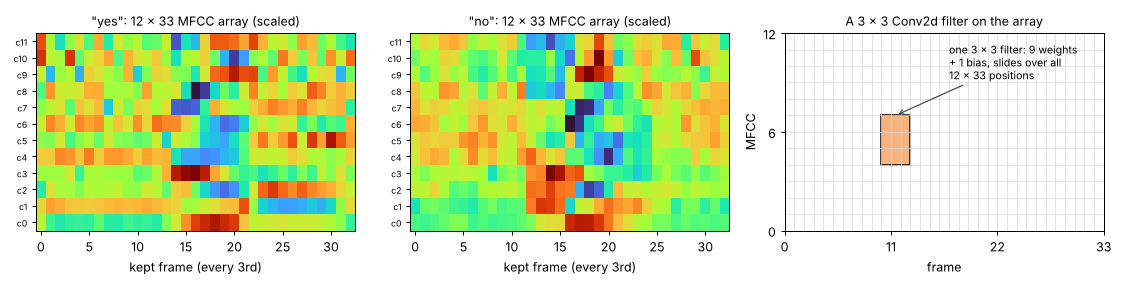

## A.2 The 2-layer Conv2D model
Each block is convolution → batch normalization → ReLU → 2 × 2 max pooling (which halves both sizes). After the second
block, averaging over the remaining 3 × 8 positions leaves 64 numbers, and a linear layer gives the 35 word scores.

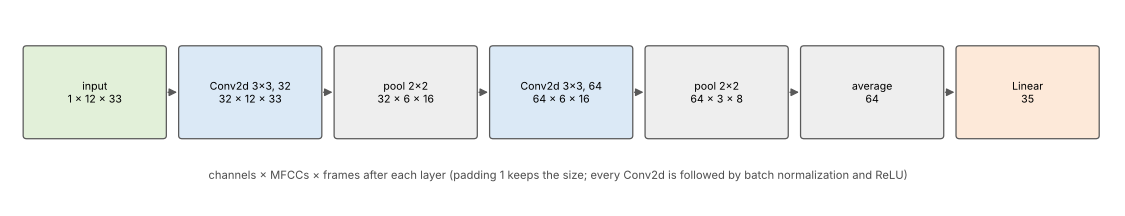

## A.3 Counting the trainable parameters

| Layer | Count | Parameters |
|---|---|---|
| Conv2d 1 | 32 filters × (3·3·1 weights + 1 bias) | 320 |
| BatchNorm 1 | 32 × (scale + shift) | 64 |
| Conv2d 2 | 64 filters × (3·3·32 weights + 1 bias) | 18,496 |
| BatchNorm 2 | 64 × (scale + shift) | 128 |
| Linear | 35 × (64 weights + 1 bias) | 2,275 |
| **Total** | | **21,283** |

For comparison, M5 in Problem 3 has 26,915 parameters; its first layer alone has 32 × (80 + 1) = 2,592.